# Load libraries

In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil
from ratio import find_power_vals

# Load humans

In [2]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

# Load snps

In [3]:
chrom = 21

In [6]:
os.listdir(f"/mnt/d/swampy_data/genotype/raw_LDs/chrom_{chrom}")[-20:-19]

[]

In [7]:
for LDs in os.listdir(f"/mnt/d/swampy_data/genotype/raw_LDs/chrom_{chrom}")[-10:-9]:
    LDblock = pd.read_pickle(f"/mnt/d/swampy_data/genotype/raw_LDs/chrom_{chrom}/{LDs}")
    snps = pd.read_pickle(f"/mnt/d/swampy_data/genotype/raw/chrom_{chrom}/{LDs}")

In [8]:
snps['super_pop'] = humans['super_pop']
snps['pop'] = humans['pop']

### Divide in ancestries

In [9]:
snps['ancestry'] = humans['super_pop']
snps['ancestry'].mask(snps['super_pop'] == 'AFR', 0, inplace=True)
snps['ancestry'].mask(snps['super_pop'] == 'AMR', 1, inplace=True)
snps['ancestry'].mask(snps['super_pop'] == 'EAS', 2, inplace=True)
snps['ancestry'].mask(snps['super_pop'] == 'EUR', 3, inplace=True)
snps['ancestry'].mask(snps['super_pop'] == 'SAS', 4, inplace=True)
afr = snps.loc[snps['ancestry'] == 0]
amr = snps.loc[snps['ancestry'] == 1]
eas = snps.loc[snps['ancestry'] == 2]
eur = snps.loc[snps['ancestry'] == 3]
sas = snps.loc[snps['ancestry'] == 4]

In [10]:
tot_mafs = []
for i in range(len(snps.columns))[0:-3]:
    snps[snps.columns[i]].value_counts()
    num_maj = snps[snps.columns[i]].value_counts()[1]
    num_het = snps[snps.columns[i]].value_counts()[0]
    try:
        num_min = snps[snps.columns[i]].value_counts()[-1]
    except Exception as e:
        num_min = 0
    total_humans = num_maj + num_het + num_min
    tot_mafs.append((num_min*2 + num_het)/(total_humans*2))

In [11]:
afr_mafs = []
for i in range(len(afr.columns))[0:-3]:
    afr[afr.columns[i]].value_counts()
    try:
        num_maj = afr[afr.columns[i]].value_counts()[1]
        try:
            num_het = afr[afr.columns[i]].value_counts()[0]
            try:
                num_min = afr[afr.columns[i]].value_counts()[-1]
            except Exception as e:
                num_min = 0
        except Exception as e: 
            num_het = 0
    except Exception as e:
        num_maj = 0
    total_humans = num_maj + num_het + num_min
    afr_mafs.append((num_min*2 + num_het)/(total_humans*2))

In [12]:
amr_mafs = []
for i in range(len(amr.columns))[0:-3]:
    amr[amr.columns[i]].value_counts()
    try:
        num_maj = amr[amr.columns[i]].value_counts()[1]
        try:
            num_het = amr[amr.columns[i]].value_counts()[0]
            try:
                num_min = amr[amr.columns[i]].value_counts()[-1]
            except Exception as e:
                num_min = 0
        except Exception as e: 
            num_het = 0
    except Exception as e:
        num_maj = 0
    total_humans = num_maj + num_het + num_min
    amr_mafs.append((num_min*2 + num_het)/(total_humans*2))

In [13]:
eur_mafs = []
for i in range(len(eur.columns))[0:-3]:
    eur[eur.columns[i]].value_counts()
    try:
        num_maj = eur[eur.columns[i]].value_counts()[1]
        try:
            num_het = eur[eur.columns[i]].value_counts()[0]
            try:
                num_min = eur[eur.columns[i]].value_counts()[-1]
            except Exception as e:
                num_min = 0
        except Exception as e: 
            num_het = 0
    except Exception as e:
        num_maj = 0
    total_humans = num_maj + num_het + num_min
    eur_mafs.append((num_min*2 + num_het)/(total_humans*2))

In [14]:
sas_mafs = []
for i in range(len(sas.columns))[0:-3]:
    sas[sas.columns[i]].value_counts()
    try:
        num_maj = sas[sas.columns[i]].value_counts()[1]
        try:
            num_het = sas[sas.columns[i]].value_counts()[0]
            try:
                num_min = sas[sas.columns[i]].value_counts()[-1]
            except Exception as e:
                num_min = 0
        except Exception as e: 
            num_het = 0
    except Exception as e:
        num_maj = 0
    total_humans = num_maj + num_het + num_min
    sas_mafs.append((num_min*2 + num_het)/(total_humans*2))

In [15]:
eas_mafs = []
for i in range(len(eas.columns))[0:-3]:
    eas[eas.columns[i]].value_counts()
    try:
        num_maj = eas[eas.columns[i]].value_counts()[1]
        try:
            num_het = eas[eas.columns[i]].value_counts()[0]
            try:
                num_min = eas[eas.columns[i]].value_counts()[-1]
            except Exception as e:
                num_min = 0
        except Exception as e: 
            num_het = 0
    except Exception as e:
        num_maj = 0
    total_humans = num_maj + num_het + num_min
    eas_mafs.append((num_min*2 + num_het)/(total_humans*2))

In [16]:
LDblock['tot_maf'] = tot_mafs
LDblock['afr_maf'] = afr_mafs
LDblock['eur_maf'] = eur_mafs
LDblock['amr_maf'] = amr_mafs
LDblock['eas_maf'] = eas_mafs
LDblock['sas_maf'] = sas_mafs

LDblock

,dim1,dim2,tot_maf,afr_maf,eur_maf,amr_maf,eas_maf,sas_maf
21:22114483:A:G_G,-0.089934,-1.219913,0.035144,0.008321,0.029821,0.011527,0.073413,0.054192
21:43320597:C:T_C,0.609531,0.714118,0.035144,0.129349,0.001988,0.004323,0.003953,0.008114
21:46369488:A:C_A,0.721343,0.767392,0.035144,0.124054,0.002982,0.010086,0.003953,0.002045
21:20092277:C:T_T,-1.272405,-0.931975,0.035144,0.003782,0.106362,0.060519,0.003953,0.022495
21:46331859:C:G_C,-0.517212,-1.051568,0.035144,0.000756,0.022863,0.011527,0.027778,0.118609
...,...,...,...,...,...,...,...,...
21:33409045:A:G_A,0.660827,1.661034,0.051318,0.186082,0.000994,0.014409,0.007874,0.002041
21:29541520:A:T_T,-0.382855,0.170032,0.051318,0.106657,0.045726,0.059078,0.003968,0.025562
21:21686584:A:G_A,-2.229185,-0.823134,0.051318,0.006808,0.148111,0.103746,0.000992,0.026585
21:18742032:A:G_G,-1.278004,-0.347528,0.051318,0.057489,0.077535,0.060519,0.010913,0.051125


# Plotting the AF distributions

In [17]:
round(LDblock['eas_maf'].max(),3)

0.229

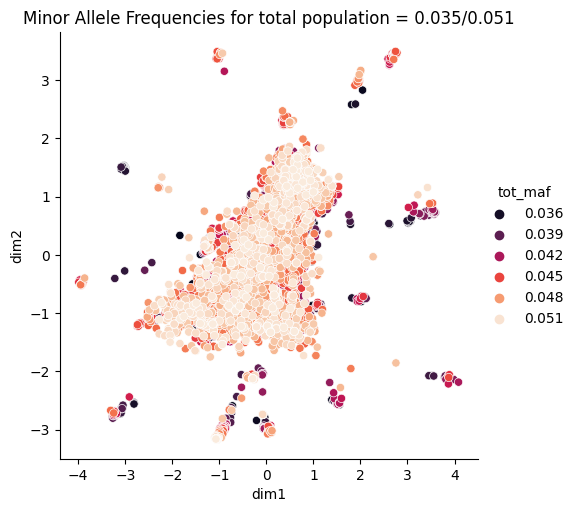

In [18]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="tot_maf",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Minor Allele Frequencies for total population = {round(LDblock['tot_maf'].min(),3)}/{round(LDblock['tot_maf'].max(),3)}")
plt.show()

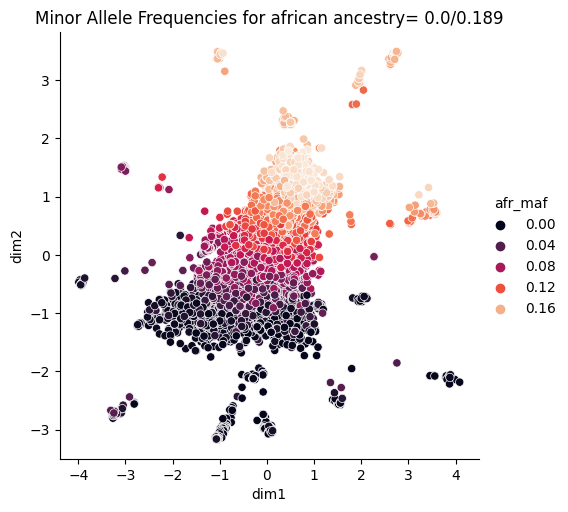

In [19]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="afr_maf",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Minor Allele Frequencies for african ancestry= {round(LDblock['afr_maf'].min(),3)}/{round(LDblock['afr_maf'].max(),3)}")
plt.show()

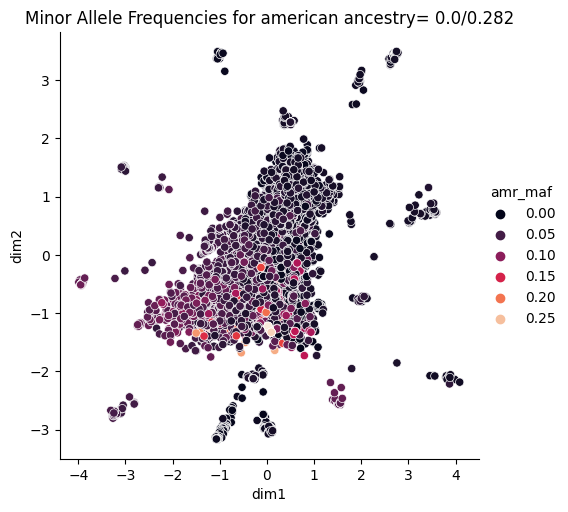

In [20]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="amr_maf",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Minor Allele Frequencies for american ancestry= {round(LDblock['amr_maf'].min(),3)}/{round(LDblock['amr_maf'].max(),3)}")
plt.show()

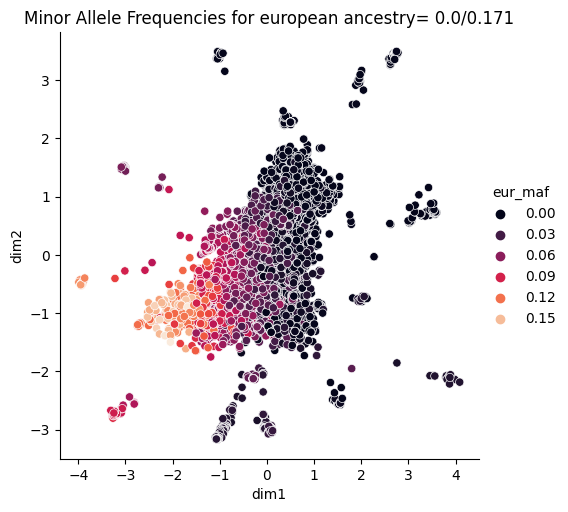

In [21]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="eur_maf",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Minor Allele Frequencies for european ancestry= {round(LDblock['eur_maf'].min(),3)}/{round(LDblock['eur_maf'].max(),3)}")
plt.show()

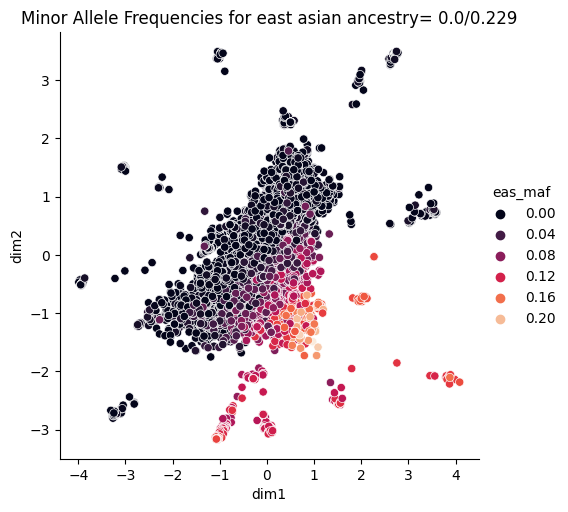

In [22]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="eas_maf",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Minor Allele Frequencies for east asian ancestry= {round(LDblock['eas_maf'].min(),3)}/{round(LDblock['eas_maf'].max(),3)}")
plt.show()

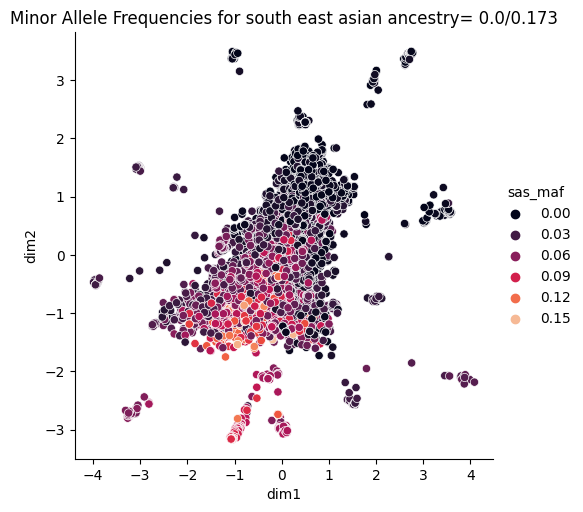

In [23]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="sas_maf",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Minor Allele Frequencies for south east asian ancestry= {round(LDblock['sas_maf'].min(),3)}/{round(LDblock['sas_maf'].max(),3)}")
plt.show()

# Clustering strategies

In [24]:
sample_size = 1000

In [25]:
LDs

'3_maf_0.035_0.051.pkl'

In [26]:
LDblock

,dim1,dim2,tot_maf,afr_maf,eur_maf,amr_maf,eas_maf,sas_maf
21:22114483:A:G_G,-0.089934,-1.219913,0.035144,0.008321,0.029821,0.011527,0.073413,0.054192
21:43320597:C:T_C,0.609531,0.714118,0.035144,0.129349,0.001988,0.004323,0.003953,0.008114
21:46369488:A:C_A,0.721343,0.767392,0.035144,0.124054,0.002982,0.010086,0.003953,0.002045
21:20092277:C:T_T,-1.272405,-0.931975,0.035144,0.003782,0.106362,0.060519,0.003953,0.022495
21:46331859:C:G_C,-0.517212,-1.051568,0.035144,0.000756,0.022863,0.011527,0.027778,0.118609
...,...,...,...,...,...,...,...,...
21:33409045:A:G_A,0.660827,1.661034,0.051318,0.186082,0.000994,0.014409,0.007874,0.002041
21:29541520:A:T_T,-0.382855,0.170032,0.051318,0.106657,0.045726,0.059078,0.003968,0.025562
21:21686584:A:G_A,-2.229185,-0.823134,0.051318,0.006808,0.148111,0.103746,0.000992,0.026585
21:18742032:A:G_G,-1.278004,-0.347528,0.051318,0.057489,0.077535,0.060519,0.010913,0.051125


In [27]:
snps = snps.T
snps

,0,1,2,3,4,5,6,7,8,9,...,2494,2495,2496,2497,2498,2499,2500,2501,2502,2503
21:22114483:A:G_G,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
21:43320597:C:T_C,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
21:46369488:A:C_A,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
21:20092277:C:T_T,0,1,1,1,1,0,1,1,1,0,...,1,1,1,1,1,1,1,1,1,1
21:46331859:C:G_C,1,1,1,1,1,1,1,1,1,1,...,1,1,0,-1,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21:18742032:A:G_G,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
21:17935194:C:G_G,1,1,1,1,0,0,0,0,1,1,...,1,1,1,1,1,0,1,1,0,1
super_pop,EUR,EUR,EUR,EUR,EUR,EUR,EUR,EUR,EUR,EUR,...,SAS,SAS,SAS,SAS,SAS,SAS,SAS,SAS,SAS,SAS
pop,GBR,GBR,GBR,GBR,GBR,GBR,GBR,GBR,GBR,GBR,...,GIH,GIH,GIH,GIH,GIH,GIH,GIH,GIH,GIH,GIH


# Kmeans clustering

In [28]:
num_clus = round(LDblock.shape[0]/sample_size)

size_min = sample_size - round(sample_size/5)
size_max = sample_size + round(sample_size/5)

from k_means_constrained import KMeansConstrained
clf = KMeansConstrained(
    n_clusters=num_clus,
    size_min=size_min,
    size_max=size_max,
    random_state=0
)
clf.fit_predict(np.array(LDblock))

LDblock['clusters_k_means'] = clf.labels_

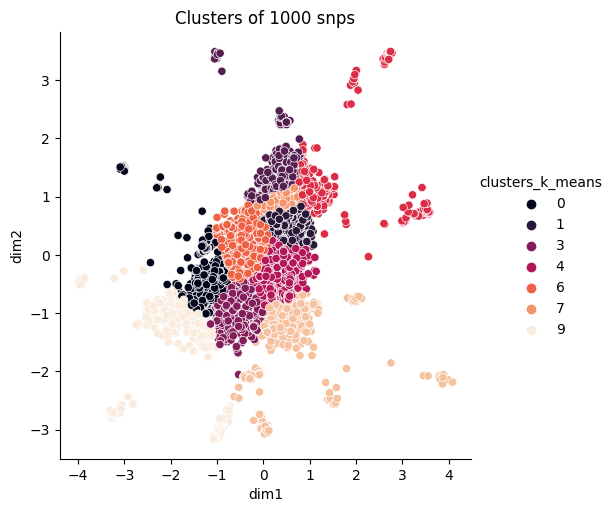

In [29]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="clusters_k_means",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Clusters of {sample_size} snps")
plt.show()

## Try DBSCAN

In [30]:
LDblock

,dim1,dim2,tot_maf,afr_maf,eur_maf,amr_maf,eas_maf,sas_maf,clusters_k_means
21:22114483:A:G_G,-0.089934,-1.219913,0.035144,0.008321,0.029821,0.011527,0.073413,0.054192,3
21:43320597:C:T_C,0.609531,0.714118,0.035144,0.129349,0.001988,0.004323,0.003953,0.008114,1
21:46369488:A:C_A,0.721343,0.767392,0.035144,0.124054,0.002982,0.010086,0.003953,0.002045,1
21:20092277:C:T_T,-1.272405,-0.931975,0.035144,0.003782,0.106362,0.060519,0.003953,0.022495,0
21:46331859:C:G_C,-0.517212,-1.051568,0.035144,0.000756,0.022863,0.011527,0.027778,0.118609,3
...,...,...,...,...,...,...,...,...,...
21:33409045:A:G_A,0.660827,1.661034,0.051318,0.186082,0.000994,0.014409,0.007874,0.002041,2
21:29541520:A:T_T,-0.382855,0.170032,0.051318,0.106657,0.045726,0.059078,0.003968,0.025562,6
21:21686584:A:G_A,-2.229185,-0.823134,0.051318,0.006808,0.148111,0.103746,0.000992,0.026585,9
21:18742032:A:G_G,-1.278004,-0.347528,0.051318,0.057489,0.077535,0.060519,0.010913,0.051125,0


In [31]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=500)
labels = dbscan.fit_predict(np.array(LDblock[['dim1','dim2']]))

# Print the cluster labels (-1 indicates an outlier)
LDblock['clusters_db_scans'] = labels

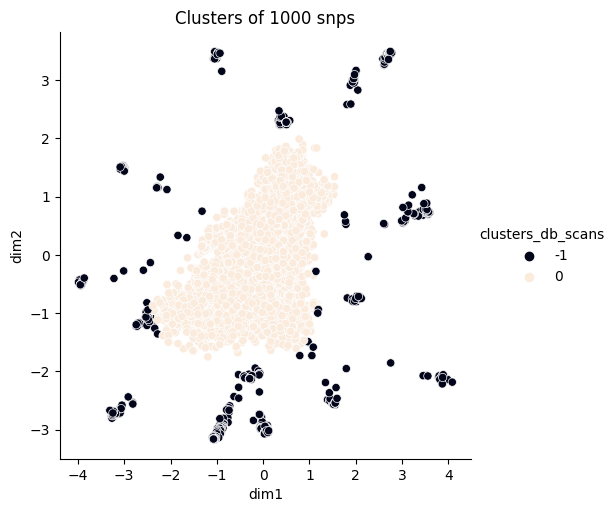

In [32]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="clusters_db_scans",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Clusters of {sample_size} snps")
plt.show()

In [33]:
LDblock['outliers_db_scan'] = LDblock['clusters_db_scans']
LDblock['outliers_db_scan'].mask(LDblock['clusters_db_scans'] == -1, 'outlier', inplace=True)
LDblock['outliers_db_scan'].mask(LDblock['clusters_db_scans'] != -1, 'clustered', inplace=True)

In [34]:
nr_outliers = LDblock['outliers_db_scan'].value_counts().outlier

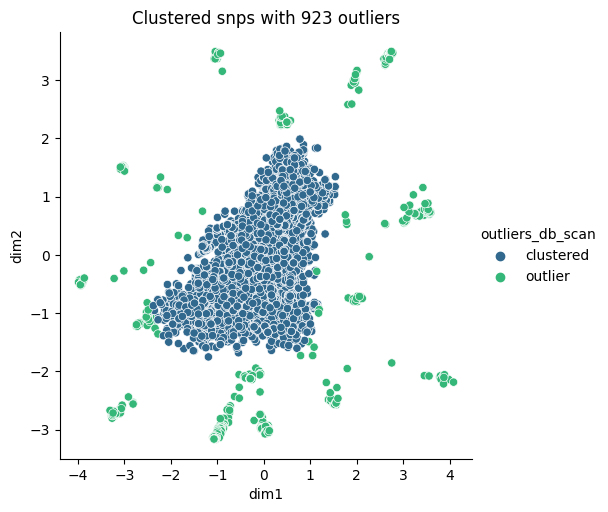

In [35]:
g = sns.relplot(
    data=LDblock,
    x=f"dim1", y=f"dim2",
    hue="outliers_db_scan",
    palette='viridis', sizes=(10, 200)).set(
    title=f"Clustered snps with {nr_outliers} outliers")
plt.show()

In [36]:
LDblock

,dim1,dim2,tot_maf,afr_maf,eur_maf,amr_maf,eas_maf,sas_maf,clusters_k_means,clusters_db_scans,outliers_db_scan
21:22114483:A:G_G,-0.089934,-1.219913,0.035144,0.008321,0.029821,0.011527,0.073413,0.054192,3,0,clustered
21:43320597:C:T_C,0.609531,0.714118,0.035144,0.129349,0.001988,0.004323,0.003953,0.008114,1,0,clustered
21:46369488:A:C_A,0.721343,0.767392,0.035144,0.124054,0.002982,0.010086,0.003953,0.002045,1,0,clustered
21:20092277:C:T_T,-1.272405,-0.931975,0.035144,0.003782,0.106362,0.060519,0.003953,0.022495,0,0,clustered
21:46331859:C:G_C,-0.517212,-1.051568,0.035144,0.000756,0.022863,0.011527,0.027778,0.118609,3,0,clustered
...,...,...,...,...,...,...,...,...,...,...,...
21:33409045:A:G_A,0.660827,1.661034,0.051318,0.186082,0.000994,0.014409,0.007874,0.002041,2,0,clustered
21:29541520:A:T_T,-0.382855,0.170032,0.051318,0.106657,0.045726,0.059078,0.003968,0.025562,6,0,clustered
21:21686584:A:G_A,-2.229185,-0.823134,0.051318,0.006808,0.148111,0.103746,0.000992,0.026585,9,0,clustered
21:18742032:A:G_G,-1.278004,-0.347528,0.051318,0.057489,0.077535,0.060519,0.010913,0.051125,0,0,clustered
